In [1]:
from rdkit import Chem
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
from rules import execute_step, prepare_molecule
import helper
from ml_helper import make_fingerprint
import xgboost
import pickle
import random
import json

In [10]:
import os

# Load some existing arrows
num_dirs = len([name for name in os.listdir('training') if os.path.isdir(os.path.join('training', name))])
random_dir = random.randint(1, num_dirs + 1)
with open(f'training/{random_dir}/sm.pkl', 'rb') as f:
    sm = pickle.load(f)
num_arrows = len([fname for fname in os.listdir(f'training/{random_dir}') if fname.startswith('mol_')])
random_mol = random.randint(0, num_arrows)
with open(f'training/{random_dir}/mol_{random_mol}.pkl', 'rb') as f:
    next_mol = pickle.load(f)

with open(f'training/{random_dir}/data.json', 'r') as f:
    j_data = json.load(f)

mech = j_data['choices'][str(random_mol)]['mechanism']

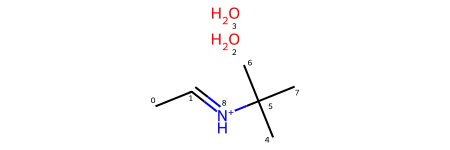

In [11]:
sm

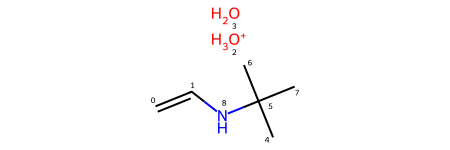

In [12]:
next_mol

In [13]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [14]:
mech

[8, 2, 0, 1, 8]

In [15]:
is_next_step = True
next_step = [0,0,0,0,0]

In [16]:
prepare_molecule(next_mol)
pot_source =next_mol.GetAtomWithIdx(mech[2])
if pot_source.HasProp('source'):
    for a in next_mol.GetAtomWithIdx(mech[2]).GetNeighbors():
        if a.HasProp('sink'):
            print(a.GetIdx(), a.GetSymbol(), a.GetProp('sink'))

pot_sink =next_mol.GetAtomWithIdx(mech[1])
if pot_source.HasProp('sink'):
    for a in next_mol.GetAtomWithIdx(mech[2]).GetNeighbors():
        if a.HasProp('source'):
            print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))

In [11]:
for a in next_mol.GetAtoms():
    if a.HasProp('source'):
        print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))